# When Does VaR Stop Working?
## A Diagnostic Framework for Market-Risk Model Failure

**Objective:** Compare Historical Simulation, Gaussian, and Student-t Value at Risk (VaR) using rolling out-of-sample forecasts.

**Dataset:** Microsoft (MSFT) daily closing prices, 2 February 2000 – 31 December 2025.

**Configuration**
- Rolling estimation window: 500 observations
- VaR confidence level: 95%
- Volatility window: 20 observations
- High-volatility threshold: 90th percentile of full-sample rolling volatility

### Research questions
1. Do the models achieve the expected 5% breach rate?
2. Does model performance change during high-volatility periods?
3. Do breaches cluster over time?
4. What can breach diagnostics tell us—and what can they not establish?

### Important limitations
The source data contains closing prices rather than adjusted closing prices. The volatility threshold uses the full sample, making the regime classification retrospective rather than a real-time signal.


In [2]:
from pathlib import Path
import sys
import os

# Find the project root by searching the current directory and its parents.
current = Path.cwd().resolve()
ROOT = None

for candidate in [current, *current.parents]:
    if (
        (candidate / "src" / "backtesting.py").exists()
        and (candidate / "data" / "market_prices.csv").exists()
    ):
        ROOT = candidate
        break

if ROOT is None:
    raise FileNotFoundError(
        "Cannot locate the project root. "
        f"Notebook started in: {current}"
    )

# Add the project root so Python can import the src package.
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.backtesting import rolling_var_backtest
from src.diagnostics import kupiec_test, breach_clustering
from src.regime_analysis import (
    analyze_volatility_regimes,
    summarize_breaches_by_regime,
)

REPORTS_DIR = ROOT / "reports"
DATA_PATH = ROOT / "data" / "market_prices.csv"

ROLLING_WINDOW = 500
CONFIDENCE_LEVEL = 0.95
VOLATILITY_WINDOW = 20
STRESS_QUANTILE = 0.90

print("Project root:", ROOT)
print("Dataset exists:", DATA_PATH.exists())
print("Python executable:", sys.executable)

Project root: C:\Users\swaya\Documents\var-model-failure-detector
Dataset exists: True
Python executable: c:\Users\swaya\anaconda3\python.exe


In [3]:
# Load the market-price dataset
prices = pd.read_csv(DATA_PATH)

# Validate required columns
required_columns = {"Date", "Close"}
missing_columns = required_columns - set(prices.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Clean and validate the data
prices["Date"] = pd.to_datetime(prices["Date"], errors="coerce")
prices["Close"] = pd.to_numeric(prices["Close"], errors="coerce")

prices = prices.dropna(subset=["Date", "Close"])
prices = prices[
    np.isfinite(prices["Close"]) & (prices["Close"] > 0)
]

prices = (
    prices.sort_values("Date")
    .drop_duplicates(subset="Date", keep="last")
    .reset_index(drop=True)
)

# Calculate daily simple returns
prices["return"] = prices["Close"].pct_change()

returns_data = prices.dropna(subset=["return"]).copy()
returns = returns_data["return"].reset_index(drop=True)
return_dates = returns_data["Date"].reset_index(drop=True)

# Validate the resulting return series
if not np.isfinite(returns.to_numpy()).all():
    raise ValueError("Returns contain missing or infinite values.")

if (returns <= -1).any():
    raise ValueError("A simple return cannot be less than or equal to -100%.")

print("DATA VALIDATION")
print("-" * 45)
print(f"Price observations: {len(prices):,}")
print(f"Daily returns:      {len(returns):,}")
print(f"First date:         {prices['Date'].min().date()}")
print(f"Last date:          {prices['Date'].max().date()}")
print(f"Missing returns:    {returns.isna().sum()}")
print(f"Mean daily return:  {returns.mean():.6%}")
print(f"Daily volatility:   {returns.std():.6%}")
print(f"Minimum return:     {returns.min():.6%}")
print(f"Maximum return:     {returns.max():.6%}")

display(prices.head())

DATA VALIDATION
---------------------------------------------
Price observations: 6,518
Daily returns:      6,517
First date:         2000-02-02
Last date:          2025-12-31
Missing returns:    0
Mean daily return:  0.058149%
Daily volatility:   1.884732%
Minimum return:     -15.598751%
Maximum return:     19.554948%


,Date,Open,High,Low,Close,Volume,return
0,2000-02-02,35.3239,35.8355,34.6530,34.7606,7.238901e+07,NaN
1,2000-02-03,35.1909,35.9200,34.5219,35.7297,7.133093e+07,0.027879
2,2000-02-04,35.9812,37.2360,35.8967,36.7435,8.029247e+07,0.028374
3,2000-02-07,36.8280,36.8531,35.9425,36.7579,5.801754e+07,0.000392
4,2000-02-08,36.6969,37.9270,36.6969,37.9028,8.154489e+07,0.031147


In [4]:
# Generate rolling out-of-sample VaR forecasts
print("Running rolling VaR backtest...")
print("This may take a little time because Student-t VaR is fitted repeatedly.")

backtest = rolling_var_backtest(
    returns.to_numpy(),
    window=ROLLING_WINDOW,
    confidence=CONFIDENCE_LEVEL,
)

# Attach the correct dates to the forecast rows
forecast_dates = return_dates.iloc[ROLLING_WINDOW:].reset_index(drop=True)
backtest.insert(0, "Date", forecast_dates)

# Verify the results
expected_forecasts = len(returns) - ROLLING_WINDOW

assert len(backtest) == expected_forecasts
assert backtest["Date"].is_monotonic_increasing

var_columns = [
    "historical_var",
    "gaussian_var",
    "student_t_var",
]

print("\nROLLING BACKTEST COMPLETE")
print("-" * 45)
print(f"Forecast observations: {len(backtest):,}")
print(f"First forecast date:   {backtest['Date'].min().date()}")
print(f"Last forecast date:    {backtest['Date'].max().date()}")
print(f"Rolling window:        {ROLLING_WINDOW}")
print(f"Confidence level:      {CONFIDENCE_LEVEL:.0%}")

print("\nVaR forecast summary (daily loss thresholds):")
display(backtest[var_columns].describe().T)

print("\nFirst five forecasts:")
display(backtest.head())

Running rolling VaR backtest...
This may take a little time because Student-t VaR is fitted repeatedly.

ROLLING BACKTEST COMPLETE
---------------------------------------------
Forecast observations: 6,017
First forecast date:   2002-02-04
Last forecast date:    2025-12-31
Rolling window:        500
Confidence level:      95%

VaR forecast summary (daily loss thresholds):


,count,mean,std,min,25%,50%,75%,max
historical_var,6017.0,0.026075,0.008466,0.013214,0.019831,0.023547,0.031264,0.050441
gaussian_var,6017.0,0.027909,0.008670,0.015060,0.022283,0.024212,0.033345,0.052724
student_t_var,6017.0,0.027516,0.008551,0.014907,0.022003,0.023803,0.032538,0.051982



First five forecasts:


,Date,position,realized_return,realized_loss,historical_var,gaussian_var,student_t_var,confidence,historical_breach,gaussian_breach,student_t_breach
0,2002-02-04,500,-0.024407,0.024407,0.050441,0.052553,0.051821,0.95,False,False,False
1,2002-02-05,501,0.000370,-0.000370,0.050441,0.052645,0.051912,0.95,False,False,False
2,2002-02-06,502,-0.012110,0.012110,0.050441,0.052658,0.051920,0.95,False,False,False
3,2002-02-07,503,-0.010031,0.010031,0.050441,0.052690,0.051953,0.95,False,False,False
4,2002-02-08,504,0.014270,-0.014270,0.050441,0.052724,0.051982,0.95,False,False,False


In [5]:
# Calculate unconditional coverage and breach-clustering diagnostics
diagnostic_rows = []

for model in ("historical", "gaussian", "student_t"):
    breaches = backtest[f"{model}_breach"].to_numpy()

    coverage = kupiec_test(
        breaches,
        confidence=CONFIDENCE_LEVEL,
    )

    clustering = breach_clustering(breaches)

    diagnostic_rows.append({
        "model": model,
        **coverage,
        **{
            f"cluster_{key}": value
            for key, value in clustering.items()
            if key != "breaches"
        },
    })

diagnostics = pd.DataFrame(diagnostic_rows)

# Add a readable interpretation of the Kupiec test
diagnostics["test_result"] = np.where(
    diagnostics["p_value"] < 0.05,
    "Reject target coverage",
    "Do not reject target coverage",
)

print("VaR BACKTEST DIAGNOSTICS")
print("-" * 60)

display(
    diagnostics[
        [
            "model",
            "observations",
            "breaches",
            "observed_rate",
            "expected_rate",
            "p_value",
            "test_result",
            "cluster_breach_clusters",
            "cluster_max_consecutive_breaches",
        ]
    ].style.format({
        "observed_rate": "{:.2%}",
        "expected_rate": "{:.2%}",
        "p_value": "{:.4f}",
    })
)

VaR BACKTEST DIAGNOSTICS
------------------------------------------------------------


,model,observations,breaches,observed_rate,expected_rate,p_value,test_result,cluster_breach_clusters,cluster_max_consecutive_breaches
0,historical,6017,307,5.10%,5.00%,0.7169,Do not reject target coverage,268,4
1,gaussian,6017,258,4.29%,5.00%,0.0094,Reject target coverage,225,3
2,student_t,6017,269,4.47%,5.00%,0.0552,Do not reject target coverage,232,3


In [6]:
# Analyze market volatility regimes
regimes = analyze_volatility_regimes(
    returns.to_numpy(),
    window=VOLATILITY_WINDOW,
    stress_quantile=STRESS_QUANTILE,
)

regimes.insert(0, "Date", return_dates)

# Align regime observations with the out-of-sample VaR forecasts
aligned_regimes = regimes.iloc[ROLLING_WINDOW:].reset_index(drop=True)

regime_summary = summarize_breaches_by_regime(
    aligned_regimes,
    backtest,
)

print("VOLATILITY REGIME ANALYSIS")
print("-" * 55)
print(f"Rolling volatility window: {VOLATILITY_WINDOW} observations")
print(f"Full-sample stress threshold: {STRESS_QUANTILE:.0%} quantile")

print("\nNumber of observations in each regime:")
display(
    aligned_regimes["regime"]
    .value_counts()
    .rename_axis("regime")
    .reset_index(name="observations")
)

print("\nVaR breach rates by regime:")
display(
    regime_summary.style.format({
        "historical_breach_rate": "{:.2%}",
        "gaussian_breach_rate": "{:.2%}",
        "student_t_breach_rate": "{:.2%}",
    })
)

VOLATILITY REGIME ANALYSIS
-------------------------------------------------------
Rolling volatility window: 20 observations
Full-sample stress threshold: 90% quantile

Number of observations in each regime:


,regime,observations
0,normal_volatility,5588
1,high_volatility,429



VaR breach rates by regime:


,regime,historical_breach_rate,gaussian_breach_rate,student_t_breach_rate
0,high_volatility,13.29%,12.35%,12.82%
1,normal_volatility,4.47%,3.67%,3.83%


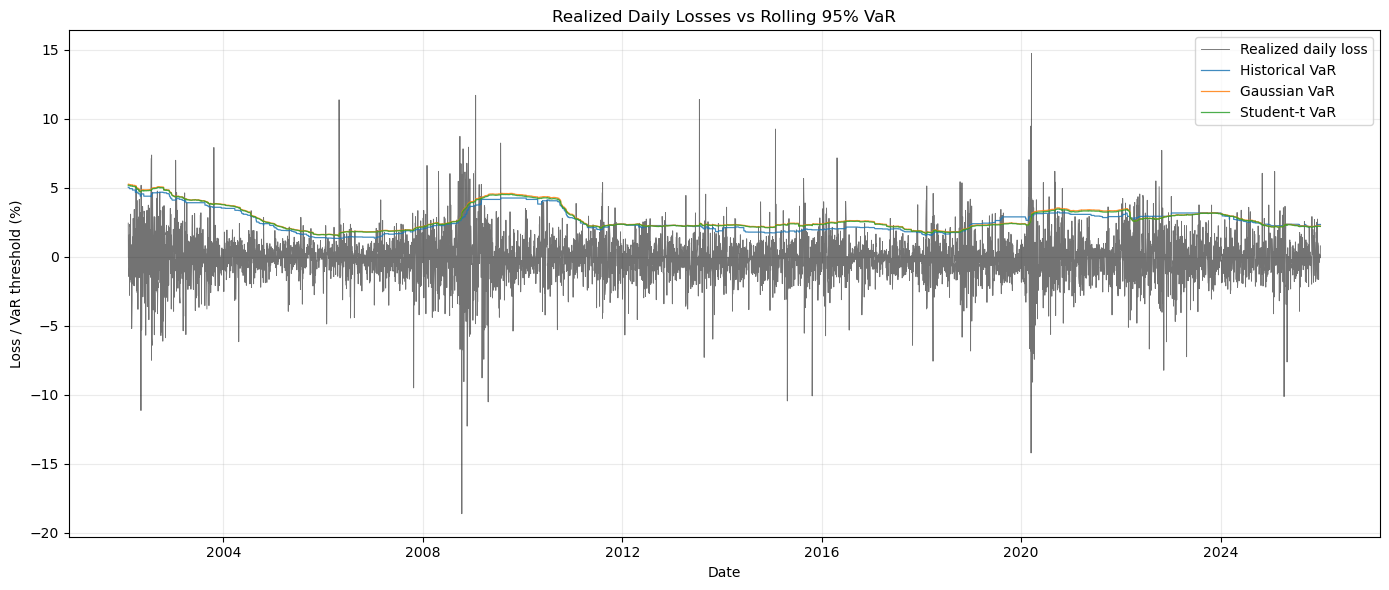

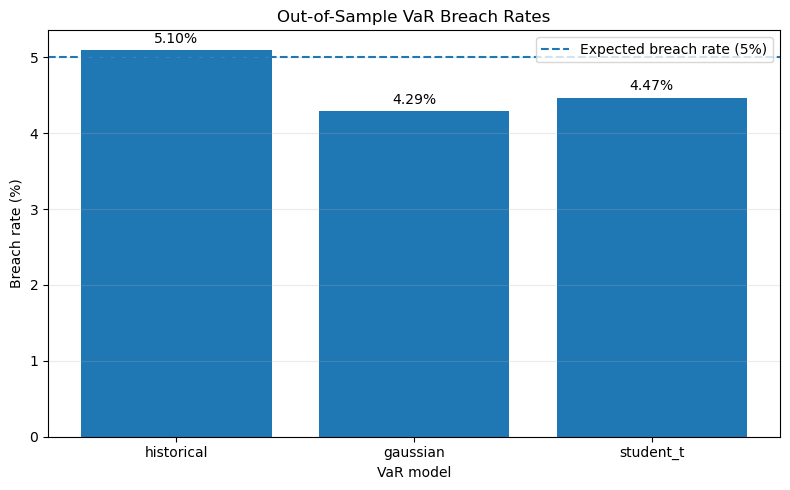

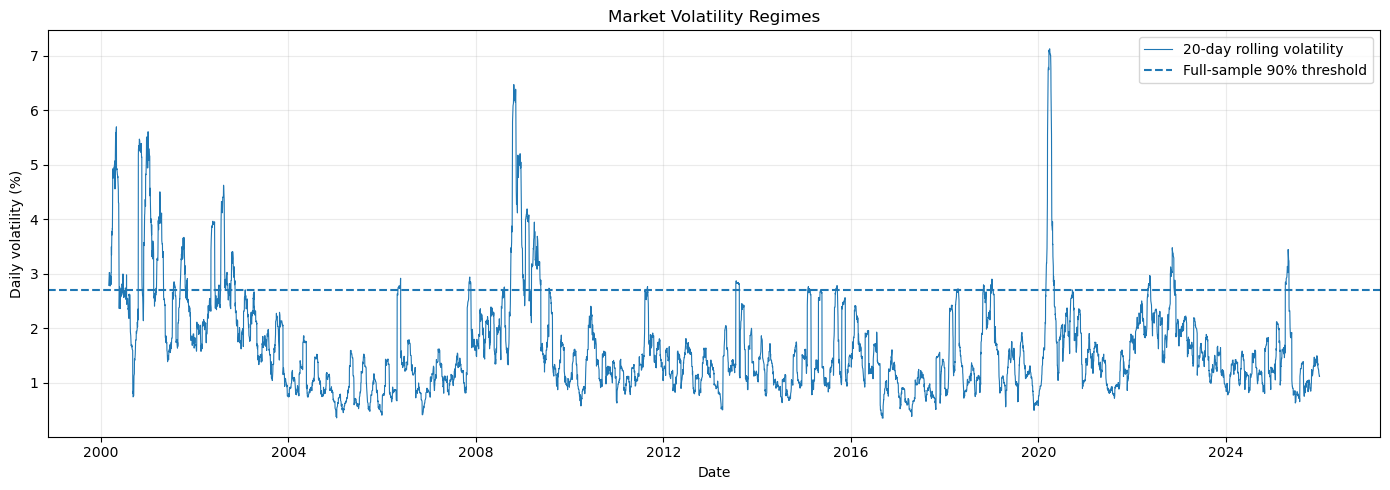

All three plots saved to: C:\Users\swaya\Documents\var-model-failure-detector\reports


In [7]:
# Create the reports directory if necessary
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Plot 1: Realized losses versus VaR forecasts
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    backtest["Date"],
    backtest["realized_loss"] * 100,
    label="Realized daily loss",
    color="black",
    linewidth=0.65,
    alpha=0.55,
)

for model, label in (
    ("historical", "Historical VaR"),
    ("gaussian", "Gaussian VaR"),
    ("student_t", "Student-t VaR"),
):
    ax.plot(
        backtest["Date"],
        backtest[f"{model}_var"] * 100,
        label=label,
        linewidth=0.9,
        alpha=0.85,
    )

ax.set_title("Realized Daily Losses vs Rolling 95% VaR")
ax.set_xlabel("Date")
ax.set_ylabel("Loss / VaR threshold (%)")
ax.legend()
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(REPORTS_DIR / "var_forecasts.png", dpi=160)
plt.show()
plt.close(fig)


# Plot 2: Observed breach rates
models = ("historical", "gaussian", "student_t")
rates = [
    backtest[f"{model}_breach"].mean() * 100
    for model in models
]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(models, rates)

ax.axhline(
    (1 - CONFIDENCE_LEVEL) * 100,
    linestyle="--",
    label="Expected breach rate (5%)",
)

ax.set_title("Out-of-Sample VaR Breach Rates")
ax.set_xlabel("VaR model")
ax.set_ylabel("Breach rate (%)")
ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.bar_label(bars, fmt="%.2f%%", padding=3)
fig.tight_layout()
fig.savefig(REPORTS_DIR / "breach_rates.png", dpi=160)
plt.show()
plt.close(fig)


# Plot 3: Rolling volatility and retrospective threshold
valid_regimes = regimes.dropna(subset=["rolling_volatility"])

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(
    valid_regimes["Date"],
    valid_regimes["rolling_volatility"] * 100,
    label=f"{VOLATILITY_WINDOW}-day rolling volatility",
    linewidth=0.8,
)

ax.axhline(
    valid_regimes["volatility_threshold"].iloc[0] * 100,
    linestyle="--",
    label=f"Full-sample {STRESS_QUANTILE:.0%} threshold",
)

ax.set_title("Market Volatility Regimes")
ax.set_xlabel("Date")
ax.set_ylabel("Daily volatility (%)")
ax.legend()
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(REPORTS_DIR / "volatility_regimes.png", dpi=160)
plt.show()
plt.close(fig)

print("All three plots saved to:", REPORTS_DIR)

In [8]:
# Save notebook results to the reports directory
backtest.to_csv(
    REPORTS_DIR / "var_backtest_results.csv",
    index=False,
)

diagnostics.to_csv(
    REPORTS_DIR / "diagnostics_summary.csv",
    index=False,
)

regime_summary.to_csv(
    REPORTS_DIR / "regime_breach_summary.csv",
    index=False,
)

regimes.to_csv(
    REPORTS_DIR / "volatility_regimes.csv",
    index=False,
)

print("Saved research outputs:")
for filename in (
    "var_backtest_results.csv",
    "diagnostics_summary.csv",
    "regime_breach_summary.csv",
    "volatility_regimes.csv",
    "var_forecasts.png",
    "breach_rates.png",
    "volatility_regimes.png",
):
    path = REPORTS_DIR / filename
    print(f"{filename}: {'OK' if path.exists() else 'MISSING'}")

Saved research outputs:
var_backtest_results.csv: OK
diagnostics_summary.csv: OK
regime_breach_summary.csv: OK
volatility_regimes.csv: OK
var_forecasts.png: OK
breach_rates.png: OK
volatility_regimes.png: OK
